**Задание 1**

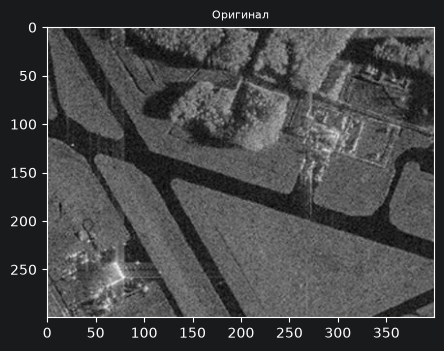

In [12]:
import numpy as np
import cv2
import matplotlib.pyplot as plt


image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


plt.figure(figsize=(5, 4))
plt.title("Оригинал", fontsize=8)
plt.imshow(image_gray, cmap='gray')
plt.show()

In [13]:
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
    if abs(av_val - img[point]) <= T:
        return True


def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image.shape, np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i, j] == 0 and mask[i - r:i + r, j - r: j + r].sum() > 0:
                    if homo_fun(image, mask, (i, j), T):
                        local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask
    return mask * 255

15
32
50
67
82
103
122
131
149
173
194
211
227
240
256
287
293
308
329
350
377
386
402
350
286
288
296
301
311
316
324
329
334
334
339
350
328
328
333
330
326
324
321
317
314
307
295
298
292
287
277
276
267
270
258
253
304
244
235
225
219
219
207
206
202
198
190
181
174
171
165
155
152
120
86
81
80
80
75
76
72
66
65
64
60
60
60
58
58
56
55
51
50
50
49
46
46
44
41
40
40
35
35
32
32
32
31
32
29
28
27
24
22
22
20
16
15
14
10
9
8
3
0


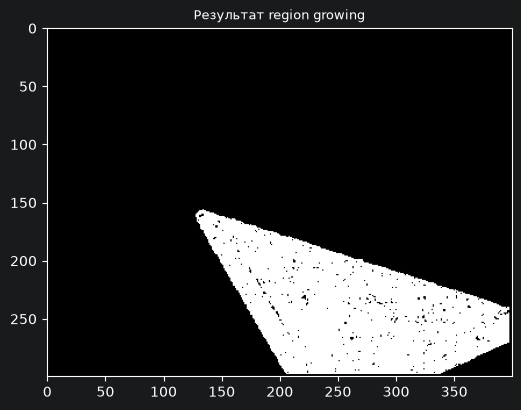

In [14]:
seed_point = (250, 250)
mask = region_growing(image_gray, seed_point, homo_average, 2, 20)

plt.figure(figsize=(6, 5))
plt.title("Результат region growing", fontsize=9)
plt.imshow(mask, cmap='gray')
plt.show()

**Задание 2**

In [15]:
def homo_local_median(img, mask, point, T):
    i, j = point
    patch = img[max(0, i-1):i+2, max(0, j-1):j+2]
    return abs(float(img[i, j]) - float(np.median(patch))) <= T


seed_cmp = (160, 132)


mask_avg  = region_growing(image_gray, seed_cmp, homo_average, 2, 20)
mask_new = region_growing(image_gray, seed_cmp, homo_local_median, 1, 5)

15
20
56
53
43
50
51
57
61
64
68
77
80
84
90
90
94
97
103
108
115
114
123
126
130
136
141
139
151
145
157
161
167
166
170
173
181
182
188
184
199
200
209
206
213
231
227
230
234
240
242
248
251
251
261
267
269
274
277
276
285
284
292
294
299
301
310
303
290
200
189
186
184
181
177
193
182
179
183
179
179
171
171
170
172
174
174
170
170
167
165
162
163
155
163
146
153
155
154
152
153
150
150
144
136
136
139
137
130
120
127
123
123
118
112
110
110
106
95
94
94
87
90
85
84
79
73
71
67
65
61
58
29
0
1
2
2
3
3
5
9
11
12
14
17
17
14
15
17
17
22
21
24
28
27
28
28
35
29
32
29
31
32
32
30
33
37
36
34
37
40
47
46
47
48
50
50
59
52
57
54
57
60
58
65
64
67
69
70
71
66
71
73
69
54
64
72
81
79
85
78
82
72
73
72
84
88
89
87
80
81
85
89
94
89
83
81
88
89
97
99
100
99
91
92
98
94
96
82
88
100
106
112
112
105
102
107
98
91
88
105
111
101
96
103
114
122
118
123
130
126
124
131
121
125
125
127
132
128
121
115
123
128
130
142
139
142
144
144
146
146
152
122
105
92
92
85
88
80
79
78
77
74
70
79
81
87
91
83


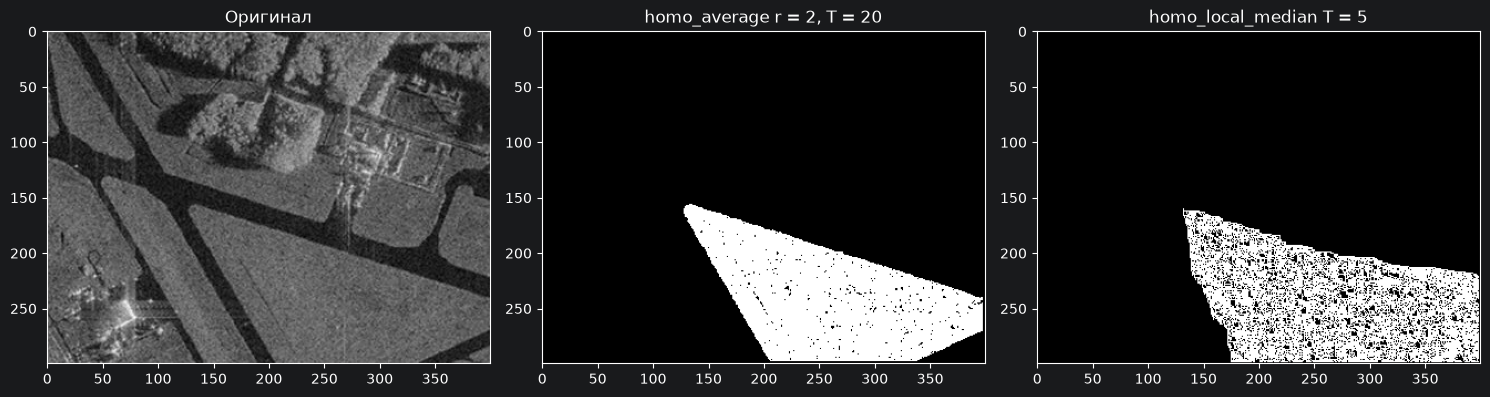

In [16]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Оригинал')

plt.subplot(1, 3, 2)
plt.imshow(mask_avg, cmap='gray')
plt.title(f'homo_average r = 2, T = 20')

plt.subplot(1, 3, 3)
plt.imshow(mask_new, cmap='gray')
plt.title(f'homo_local_median T = 5')
plt.tight_layout()
plt.show()

**Задание 3**

In [17]:
palms = cv2.imread('palm_1.JPG')
palms_gray = cv2.cvtColor(palms, cv2.COLOR_BGR2GRAY)

In [18]:
ret, thresh = cv2.threshold(palms_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)

FG_RATIO = 0.15
_, sure_fg = cv2.threshold(dist, FG_RATIO * dist.max(), 255, 0)
sure_fg = np.uint8(sure_fg)


n, lbl, stats, _ = cv2.connectedComponentsWithStats(sure_fg, connectivity=8)
clean_fg = np.zeros_like(sure_fg)
for i in range(1, n):
    if stats[i, cv2.CC_STAT_AREA] > 150:
        clean_fg[lbl == i] = 255
sure_fg = clean_fg

sure_bg = cv2.dilate(opening, kernel, iterations=3)

unknown = cv2.subtract(sure_bg, sure_fg)

_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

markers = cv2.watershed(palms, markers)

num_trees = len([l for l in np.unique(markers) if l not in (-1, 0, 1)])

palms_vis = palms.copy()
palms_vis[markers == -1] = [0, 0, 255]

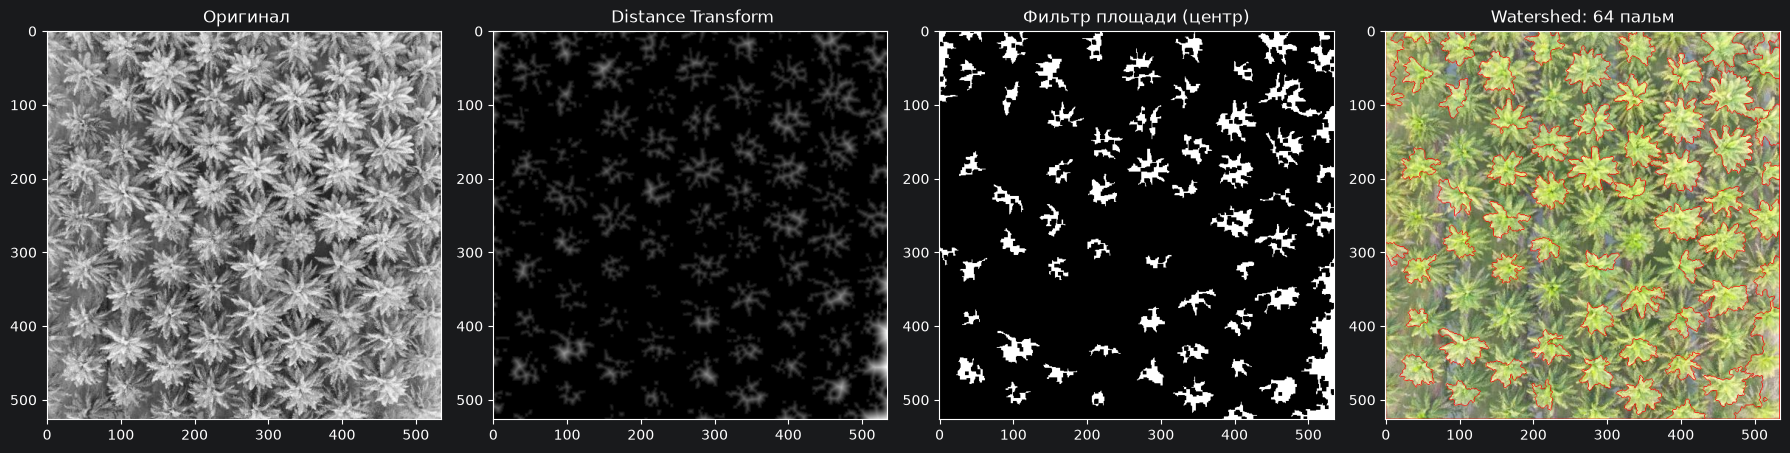

Пальм найдено: 64


In [19]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.imshow(palms_gray, cmap='gray')
plt.title(' Оригинал')

plt.subplot(1, 4, 2)
plt.imshow(dist, cmap='gray')
plt.title(' Distance Transform')

plt.subplot(1, 4, 3)
plt.imshow(sure_fg, cmap='gray')
plt.title('Фильтр площади (центр)')

plt.subplot(1, 4, 4)
plt.imshow(cv2.cvtColor(palms_vis, cv2.COLOR_BGR2RGB))
plt.title(f'Watershed: {num_trees} пальм')

plt.tight_layout()
plt.show()

print(f"Пальм найдено: {num_trees}")